# 1. Contexte métier et problématique

## 1.1 Contexte

TouNum est une entreprise spécialisée dans la numérisation de documents, notamment à partir de supports papier. Dans le cadre de l'augmentation du volume de documents numérisés, l'entreprise souhaite développer de nouveaux services reposant sur les techniques de Machine Learning.

L'un des objectifs du projet consiste à mettre en place une chaîne automatisée permettant d'analyser des images et, à terme, de générer automatiquement une légende descriptive de leur contenu.

Avant de réaliser cette étape de génération de légendes (*image captioning*), une étape de filtrage est nécessaire. En effet, l'ensemble des images numérisées par TouNum ne correspond pas nécessairement à des photographies. Le dataset peut également contenir des schémas, des graphiques, des textes scannés, des dessins ou encore des peintures.

L'objectif de ce premier livrable est donc de développer un modèle de classification capable de distinguer automatiquement :

* les **photographies** ;
* les **autres types d'images**.

Cette classification permettra de sélectionner automatiquement les photographies qui pourront ensuite être transmises aux étapes suivantes du workflow.

## 1.2 Problématique

La problématique étudiée dans ce livrable est donc la suivante :

**Comment développer un modèle de réseau de neurones capable de distinguer automatiquement une photographie d'une autre catégorie d'image dans un ensemble de documents numérisés ?**

La difficulté du problème dépend notamment de la nature des images à distinguer. Les textes scannés ou les schémas présentent généralement des caractéristiques visuelles très différentes des photographies. À l'inverse, certaines peintures possèdent un rendu très réaliste et peuvent donc être visuellement proches d'une photographie.

L'objectif sera ainsi de construire progressivement un modèle, d'évaluer ses performances et d'analyser ses limites afin de déterminer s'il est suffisamment pertinent pour être intégré au workflow de TouNum.


# 2. Objectif de la classification

Le problème est formulé comme une **classification binaire supervisée**.

Deux classes sont retenues :

| Classe | Signification | Exemples                                          |
| ------ | ------------- | ------------------------------------------------- |
| `0`    | Autre         | Schéma, graphique, texte scanné, dessin, peinture |
| `1`    | Photo         | Photographie                                      |

Les datasets fournis par TouNum sont initialement répartis dans différents répertoires selon leur nature. L'absence d'étiquette explicite dans les fichiers ne constitue donc pas un problème : la classe pourra être automatiquement déterminée à partir du répertoire dans lequel se trouve chaque image.

L'objectif final est d'obtenir un modèle capable de prendre une image en entrée et de produire une prédiction binaire :

**Image → Réseau de neurones → Photo / Autre**

Cette première classification constitue une étape de filtrage. Les images identifiées comme des photographies pourront ensuite être transmises aux étapes de traitement d'image et de génération automatique de légendes.


## 3. Importation des librairies

In [14]:
import os
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import imageio.v3 as iio
import pathlib
import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import train_test_split

print("TensorFlow :", tf.__version__)

TensorFlow : 2.21.0


## 4. Exploration et visualisation des données du dataset

Commençons tout d'abord par explorer les classes du dataset.


In [17]:
datasets_dir = pathlib.Path('datasets')

In [19]:
train_set = keras.preprocessing.image_dataset_from_directory(
    datasets_dir,
    validation_split=0.2,
    subset='training',
    seed=42
)

validation_set = keras.preprocessing.image_dataset_from_directory(
    datasets_dir,
    validation_split=0.2,
    subset='validation',
    seed=42
)


Found 39698 files belonging to 5 classes.
Using 31759 files for training.
Found 39698 files belonging to 5 classes.
Using 7939 files for validation.


In [29]:
labels = train_set.class_names

class_distribution = {
    label: sum(1 for file in (datasets_dir / label).iterdir() if file.is_file())
    for label in labels
}

print(class_distribution)

{'Painting': 8299, 'Photo': 9993, 'Schematics': 10001, 'Sketch': 1406, 'Text': 10000}


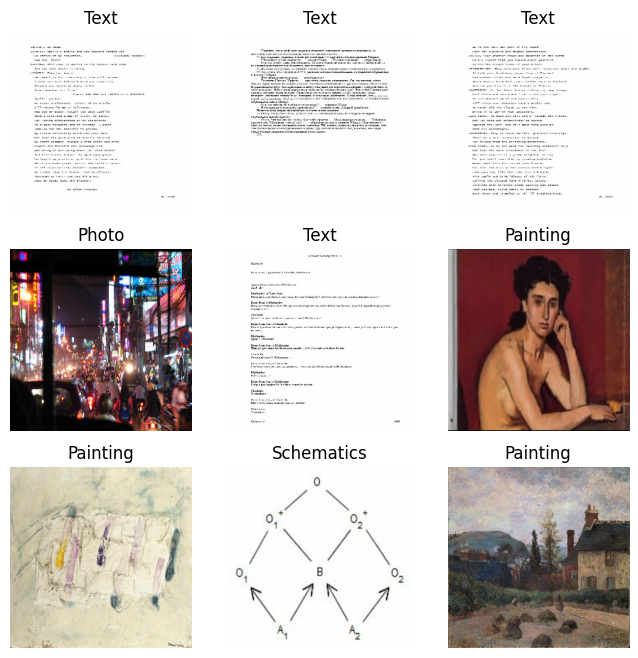

In [30]:
# Visualisation de quelques images du dataset
plt.figure(figsize=(8, 8))
for images, label in train_set.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i +1)
        ax.imshow(images[i].numpy().astype('uint8'))
        plt.title(labels[label[i]])
        plt.axis("off")

# 6. Construction du modèle CNN

Un réseau de neurones convolutif (CNN) est utilisé car il est particulièrement adapté à l'analyse d'images.

Les couches de convolution permettent d'extraire progressivement des caractéristiques visuelles :
- contours ;
- textures ;
- formes ;
- motifs plus complexes.

Les couches de MaxPooling réduisent progressivement la résolution spatiale des représentations tout en conservant les informations les plus importantes.

Une couche Flatten transforme ensuite la représentation multidimensionnelle en vecteur afin de pouvoir utiliser des couches denses pour la classification.

La dernière couche contient un seul neurone associé à une fonction d'activation sigmoïde. Elle produit une probabilité comprise entre 0 et 1 correspondant à la probabilité que l'image appartienne à la classe « Photo ».

In [7]:
img_height, img_width, batch_size = 128, 128, 32 #TODO

model_baseline = keras.Sequential([

    layers.Input(shape=(img_height, img_width, 3)),
    layers.Conv2D(32, (3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dense(1,activation="soft")
])

model_baseline.summary()

# Fonction de perte et optimiseur
model_baseline.compile(optimizer="adam",loss =  'sparse_categorical_crossentropy',metrics=['accuracy'])

## 7.1 Fonction de perte

Le problème étant une classification binaire, la fonction de perte `binary_crossentropy` est utilisée.

Elle mesure l'écart entre la probabilité prédite par le réseau et la classe réelle.

## 7.2 Optimisation

L'optimiseur Adam est utilisé pour ajuster automatiquement les poids du réseau au cours de l'entraînement.

Un taux d'apprentissage initial de 0,001 est retenu.

## 7.3 Fonction d'activation finale

La dernière couche utilise une fonction sigmoïde.

La sortie du réseau est donc comprise entre 0 et 1 :

- valeur proche de 0 → Autre ;
- valeur proche de 1 → Photo.

Un seuil de 0,5 sera utilisé pour transformer cette probabilité en prédiction binaire.

{np.int64(0): np.float64(0.6591002138015739), np.int64(1): np.float64(2.071336669049321)}
Epoch 1/5
906/906 ━━━━━━━━━━━━━━━━━━━━ 1015s 945ms/step - accuracy: 0.7728 - loss: 0.4019 - val_accuracy: 0.8575 - val_loss: 0.3009
Epoch 2/5
906/906 ━━━━━━━━━━━━━━━━━━━━ 977s 904ms/step - accuracy: 0.8304 - loss: 0.3206 - val_accuracy: 0.8441 - val_loss: 0.3172
Epoch 3/5
906/906 ━━━━━━━━━━━━━━━━━━━━ 1001s 945ms/step - accuracy: 0.8807 - loss: 0.2511 - val_accuracy: 0.8390 - val_loss: 0.3911
Epoch 4/5
906/906 ━━━━━━━━━━━━━━━━━━━━ 967s 908ms/step - accuracy: 0.9076 - loss: 0.2043 - val_accuracy: 0.8928 - val_loss: 0.2482
Epoch 5/5
906/906 ━━━━━━━━━━━━━━━━━━━━ 993s 907ms/step - accuracy: 0.9402 - loss: 0.1413 - val_accuracy: 0.8797 - val_loss: 0.2858


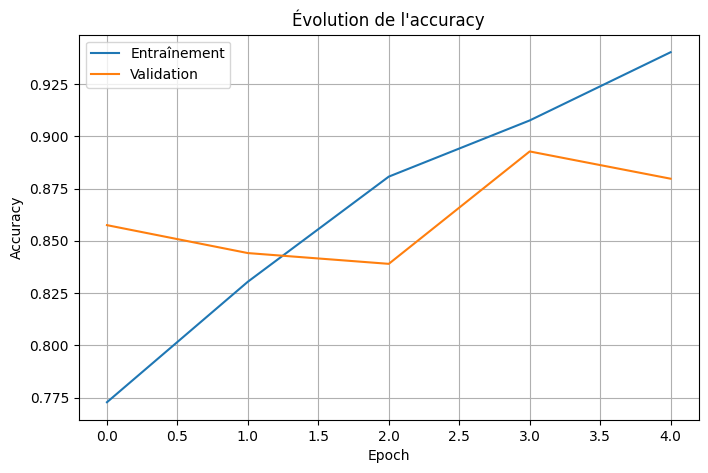

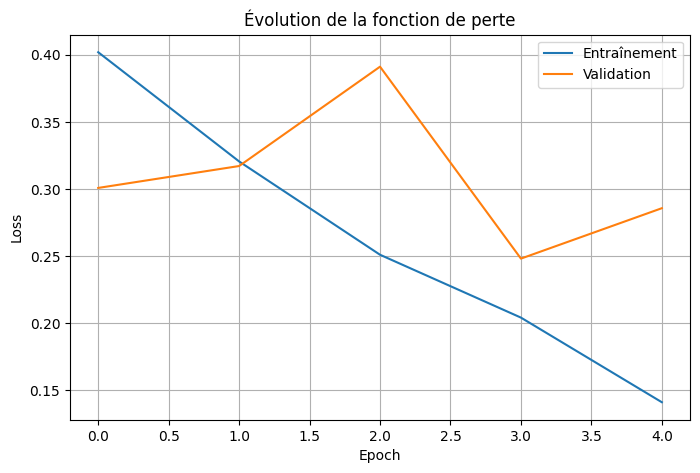

In [8]:
history_baseline = model_baseline.fit(
    train_set,
    validation_data=validation_set,
    epochs=5,
)

# Accuracy
plt.figure(figsize=(8, 5))

plt.plot(history_baseline.history["accuracy"],label="training")

plt.plot(history_baseline.history["val_accuracy"],label="Validation")

plt.title("Evolution de l'accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

# Loss

plt.figure(figsize=(8, 5))

plt.plot(history_baseline.history["loss"],label="training")

plt.plot(history_baseline.history["val_loss"],label="Validation")

plt.title("Evolution de la fonction de perte")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()